## Dataset Overview

The Iris dataset contains 150 samples from three iris species: Setosa, Versicolor, and Virginica. Each sample is described by four numerical features related to sepal and petal dimensions.

The dataset is balanced, with 50 samples per species. It also contains no missing values, so no missing-value treatment is required.

The classification task is to predict the iris species using the four measurements.

In [1]:
from sklearn.datasets import load_iris
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# Load the Dataset
iris = load_iris()
iris

{'data': array([[5.1, 3.5, 1.4, 0.2],
        [4.9, 3. , 1.4, 0.2],
        [4.7, 3.2, 1.3, 0.2],
        [4.6, 3.1, 1.5, 0.2],
        [5. , 3.6, 1.4, 0.2],
        [5.4, 3.9, 1.7, 0.4],
        [4.6, 3.4, 1.4, 0.3],
        [5. , 3.4, 1.5, 0.2],
        [4.4, 2.9, 1.4, 0.2],
        [4.9, 3.1, 1.5, 0.1],
        [5.4, 3.7, 1.5, 0.2],
        [4.8, 3.4, 1.6, 0.2],
        [4.8, 3. , 1.4, 0.1],
        [4.3, 3. , 1.1, 0.1],
        [5.8, 4. , 1.2, 0.2],
        [5.7, 4.4, 1.5, 0.4],
        [5.4, 3.9, 1.3, 0.4],
        [5.1, 3.5, 1.4, 0.3],
        [5.7, 3.8, 1.7, 0.3],
        [5.1, 3.8, 1.5, 0.3],
        [5.4, 3.4, 1.7, 0.2],
        [5.1, 3.7, 1.5, 0.4],
        [4.6, 3.6, 1. , 0.2],
        [5.1, 3.3, 1.7, 0.5],
        [4.8, 3.4, 1.9, 0.2],
        [5. , 3. , 1.6, 0.2],
        [5. , 3.4, 1.6, 0.4],
        [5.2, 3.5, 1.5, 0.2],
        [5.2, 3.4, 1.4, 0.2],
        [4.7, 3.2, 1.6, 0.2],
        [4.8, 3.1, 1.6, 0.2],
        [5.4, 3.4, 1.5, 0.4],
        [5.2, 4.1, 1.5, 0.1],
  

In [3]:
df = pd.DataFrame(iris.data , columns= iris.feature_names)
df['Target'] = iris.target
df['Species'] = df['Target'].map(dict(enumerate(iris.target_names)))

In [4]:
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),Target,Species
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


## Exploratory Data Analysis

The initial analysis shows that the dataset is balanced across all three classes, reducing the likelihood of class imbalance affecting the classification results.

Feature distributions and pairwise relationships provide useful insights into class separability. In particular, petal measurements show clearer separation between species than sepal measurements.

In [5]:
# Exploratory Data Analysis (EDA)
print("Dataset shape:", df.shape)
print("\nDataset information:")
df.info()

Dataset shape: (150, 6)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   Target             150 non-null    int64  
 5   Species            150 non-null    object 
dtypes: float64(4), int64(1), object(1)
memory usage: 7.2+ KB


In [6]:
df.describe()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),Target
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333,1.000000
std,0.828066,0.435866,1.765298,0.762238,0.819232
min,4.300000,2.000000,1.000000,0.100000,0.000000
25%,5.100000,2.800000,1.600000,0.300000,0.000000
50%,5.800000,3.000000,4.350000,1.300000,1.000000
75%,6.400000,3.300000,5.100000,1.800000,2.000000
max,7.900000,4.400000,6.900000,2.500000,2.000000


In [7]:
print(df['Species'].value_counts())

Species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


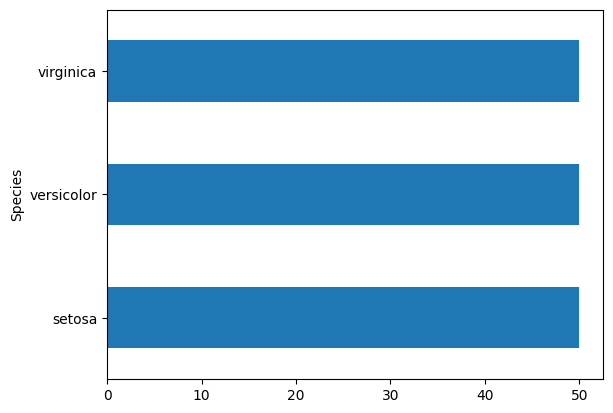

In [8]:
df['Species'].value_counts().plot(kind='barh')
plt.xticks(rotation=0)
plt.show()

## Feature Inspection

The correlation analysis reveals a strong positive relationship between petal length and petal width (0.9629). Sepal length is also strongly correlated with petal length (0.8718) and petal width (0.8179).

However, correlation alone does not determine how useful a feature is for classification. The scatter plots provide additional evidence of class separability.

Petal length and petal width offer the clearest distinction between species, particularly for Setosa. Versicolor and Virginica show some overlap, indicating that distinguishing these two classes is more challenging.

Sepal length and sepal width provide less distinct separation, with considerable overlap between Versicolor and Virginica.

In [9]:
# Feature Inspection
features = iris.feature_names
cor = df[features].corr()
cor

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
sepal length (cm),1.000000,-0.117570,0.871754,0.817941
sepal width (cm),-0.117570,1.000000,-0.428440,-0.366126
petal length (cm),0.871754,-0.428440,1.000000,0.962865
petal width (cm),0.817941,-0.366126,0.962865,1.000000


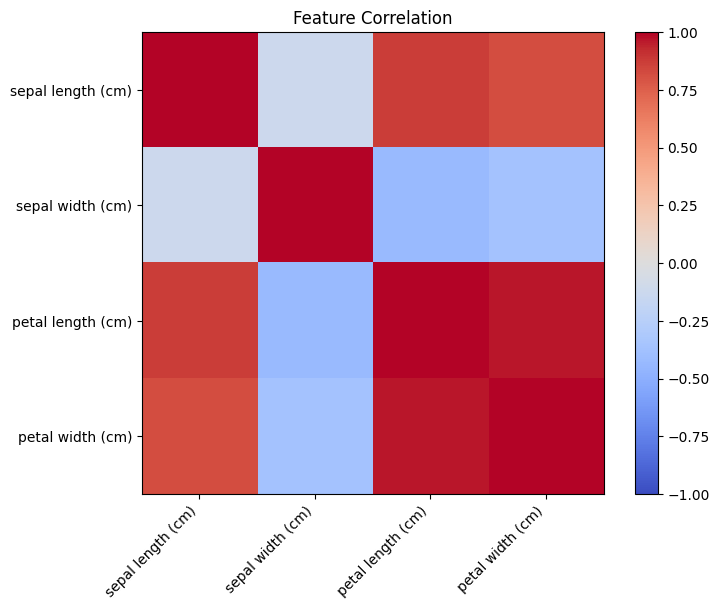

In [10]:
plt.figure(figsize=(8, 6))
plt.imshow(cor,cmap='coolwarm', vmin=-1, vmax=1)
plt.colorbar()
plt.xticks(range(len(features)), features, rotation=45, ha='right')
plt.yticks(range(len(features)), features)
plt.title('Feature Correlation')
plt.show()

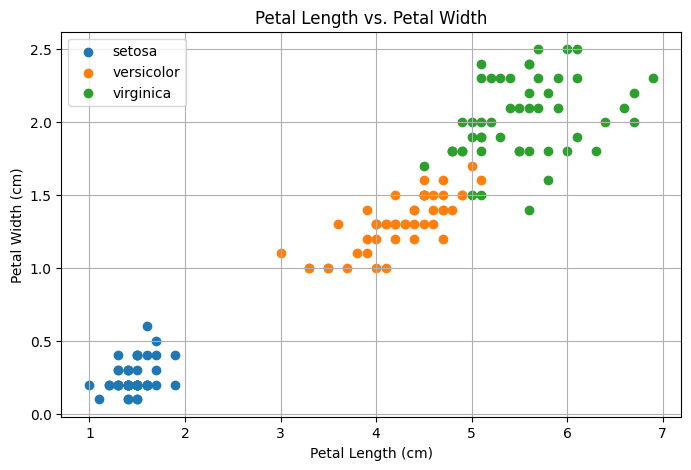

In [11]:
plt.figure(figsize=(8, 5))

for species in iris.target_names:
    subset = df[df['Species'] == species]

    plt.scatter(
        subset['petal length (cm)'],
        subset['petal width (cm)'],
        label=species
    )

plt.xlabel('Petal Length (cm)')
plt.ylabel('Petal Width (cm)')
plt.title('Petal Length vs. Petal Width')
plt.legend()
plt.grid(True)
plt.show()

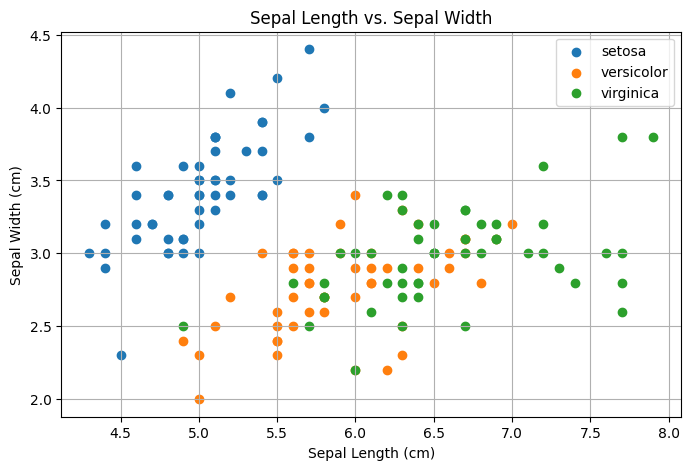

In [12]:
plt.figure(figsize=(8, 5))

for species in iris.target_names:
    subset = df[df['Species'] == species]

    plt.scatter(
        subset['sepal length (cm)'],
        subset['sepal width (cm)'],
        label=species
    )

plt.xlabel('Sepal Length (cm)')
plt.ylabel('Sepal Width (cm)')
plt.title('Sepal Length vs. Sepal Width')
plt.legend()
plt.grid(True)
plt.show()

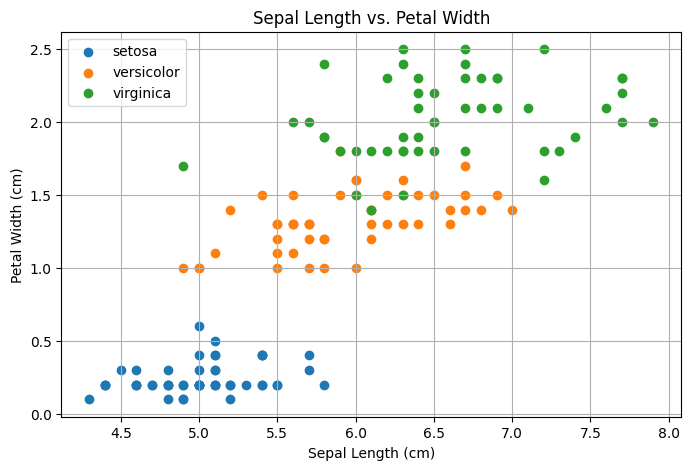

In [13]:
plt.figure(figsize=(8, 5))

for species in iris.target_names:
    subset = df[df['Species'] == species]

    plt.scatter(
        subset['sepal length (cm)'],
        subset['petal width (cm)'],
        label=species
    )

plt.xlabel('Sepal Length (cm)')
plt.ylabel('Petal Width (cm)')
plt.title('Sepal Length vs. Petal Width')
plt.legend()
plt.grid(True)
plt.show()

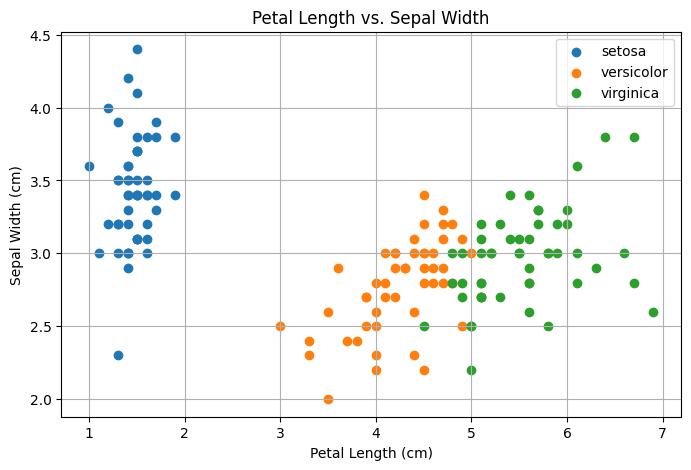

In [14]:
plt.figure(figsize=(8, 5))

for species in iris.target_names:
    subset = df[df['Species'] == species]

    plt.scatter(
        subset['petal length (cm)'],
        subset['sepal width (cm)'],
        label=species
    )

plt.xlabel('Petal Length (cm)')
plt.ylabel('Sepal Width (cm)')
plt.title('Petal Length vs. Sepal Width')
plt.legend()
plt.grid(True)
plt.show()

## Train-Test Split and Feature Scaling

The dataset is divided into training and testing subsets using an 80:20 ratio. Stratified sampling preserves the original class distribution in both subsets.

Standardization is applied to Logistic Regression and KNN because their performance can be affected by differences in feature scales. The scaler is fitted exclusively on the training data and then applied to both subsets to prevent data leakage.

Decision Tree uses the original, unscaled features because its split decisions are not dependent on feature magnitude.

In [15]:
# Train/Test Split
from sklearn.model_selection import train_test_split

x= df[iris.feature_names]
y = df['Target']

X_train, X_test, y_train, y_test = train_test_split(
    x,y,
    test_size= 0.2,
    random_state = 123,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (120, 4)
X_test: (30, 4)
y_train: (120,)
y_test: (30,)


In [16]:
# Feature Scaling
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training data mean:", X_train_scaled.mean(axis=0).round(2))
print("Training data std:", X_train_scaled.std(axis=0).round(2))

Training data mean: [-0. -0.  0. -0.]
Training data std: [1. 1. 1. 1.]


In [18]:
# Logistic Regression and KNN are sensitive to feature scaling because
# they rely on optimization and distance calculations, respectively.
# Decision Trees generally do not require feature scaling.
# Therefore, scaled data is used for Logistic Regression and KNN,
# while the original data is used for Decision Tree.

In [19]:
# Logistic Regression
from sklearn.linear_model import LogisticRegression

log_model = LogisticRegression(max_iter=200)
log_model.fit(X_train_scaled , y_train)

log_predict = log_model.predict(X_test_scaled)

In [20]:
# K-Nearest Neighbors (KNN)
from sklearn.neighbors import KNeighborsClassifier

knn_model = KNeighborsClassifier(n_neighbors = 5)
knn_model.fit(X_train_scaled , y_train)

knn_predict = knn_model.predict(X_test_scaled)

In [21]:
# Decision Tree
from sklearn.tree import DecisionTreeClassifier

dt_model = DecisionTreeClassifier(random_state=123)
dt_model.fit(X_train, y_train)

dt_predict = dt_model.predict(X_test)

## Model Evaluation

The three classifiers were evaluated on the same test set of 30 samples.

Logistic Regression achieved the highest accuracy of 93.33%, followed by KNN with 90.00%. Decision Tree obtained an accuracy of 83.33%.

The results indicate that Logistic Regression provides the best overall classification performance among the evaluated models. However, the relatively small test set means that even a single additional misclassification changes the accuracy by approximately 3.33 percentage points.

In [22]:
# Accuracy
from sklearn.metrics import accuracy_score

models = {
    'Logistic Regression': log_predict,
    'KNN': knn_predict,
    'Decision Tree': dt_predict
}

for name, predictions in models.items():
    accuracy = accuracy_score(y_test, predictions)
    print(f'{name}: {accuracy:.4f}')

Logistic Regression: 0.9333
KNN: 0.9000
Decision Tree: 0.8333


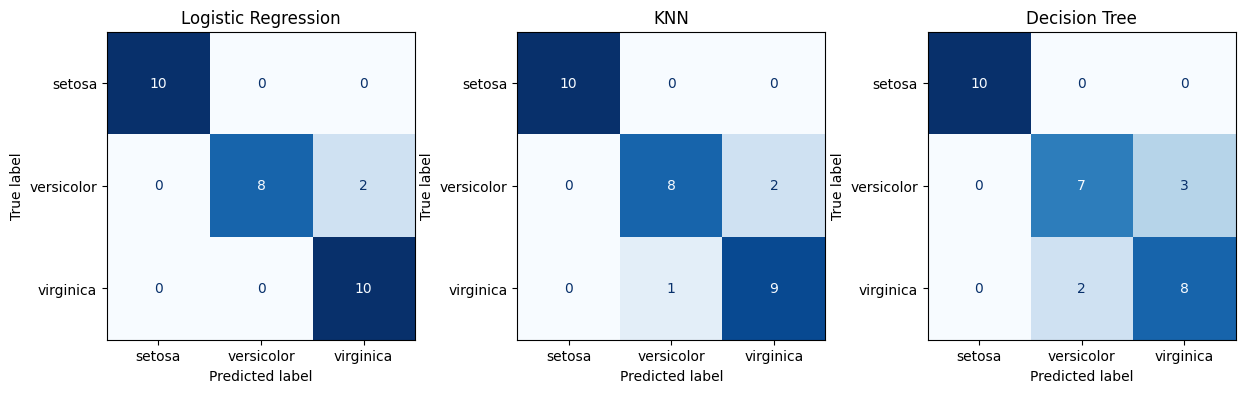

In [29]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

fig,axes = plt.subplots(1,3 , figsize=(15,4))
for ax, (name, prediction) in zip (axes , models.items()):
    c_m = confusion_matrix(y_test, prediction)

    disp = ConfusionMatrixDisplay(
        confusion_matrix = c_m,
        display_labels = iris.target_names
    )
    disp.plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name)

plt.show()

## Confusion Matrix Analysis

The confusion matrices provide further insight into the classification errors.

All three models correctly classified every Setosa sample, indicating that this species is clearly distinguishable based on the selected features.

The main classification challenge is distinguishing Versicolor from Virginica:

- **Logistic Regression:** Correctly classified all Virginica samples but misclassified two Versicolor samples as Virginica.
- **KNN:** Misclassified two Versicolor samples as Virginica and one Virginica sample as Versicolor.
- **Decision Tree:** Misclassified three Versicolor samples as Virginica and two Virginica samples as Versicolor.

Logistic Regression demonstrated the strongest class-level performance, particularly for Virginica, while Decision Tree produced the highest number of classification errors.